# Description

Exercise #1 from #381: distribution of the PnL as a function of the hit
rate.

- Load close prices for a coin at a given sampling frequency
- Compute returns with `pct_change()`
- Simulate a predictor with a given hit rate: a correct call earns |r| and a
  wrong call loses |r|
- Plot the PnL distribution and P(PnL > 0) as the hit rate changes
- Repeat for different coins and sampling frequencies

Two ways of drawing the hits are compared:
- "shuffle": exactly round(hit_rate * N) hits in random order (Exercise #1)
- "bernoulli": each call is correct with probability hit_rate (spec
  formalization)

## Imports

In [8]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import tradability_utils as tu

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Config

Change the coins, frequencies, and hit rates here.

In [9]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVALS = ["1h", "1d"]
START = "2020-01-01"
END = "2026-10-01"
# Use a fine grid around 0.50 to see where 1h crosses 95%.
HIT_RATES = [
    0.48,
    0.49,
    0.50,
    0.502,
    0.504,
    0.506,
    0.508,
    0.51,
    0.515,
    0.52,
    0.525,
    0.53,
    0.55,
]
# Show only these hit rates in the box plots, to keep them readable.
BOX_HIT_RATES = [0.48, 0.49, 0.50, 0.51, 0.52, 0.53, 0.55]
N_SIMS = 1000
MODES = ["shuffle", "bernoulli"]
# All (coin, frequency) pairs, one subplot each.
PAIRS = [(symbol, interval) for symbol in SYMBOLS for interval in INTERVALS]

## Simulate the PnL

In [10]:
# Run the experiment for every coin, frequency, and mode.
results = []
for symbol, interval in PAIRS:
    for mode in MODES:
        df = tu.run_experiment(
            symbol, interval, START, END, HIT_RATES, N_SIMS, mode=mode
        )
        results.append(df)
results = pd.concat(results, ignore_index=True)
# Show the number of trades for each coin and frequency.
n_trades = results.groupby(["symbol", "interval"])["n_trades"].first()
n_trades

symbol   interval
BTCUSDT  1d           2464
         1h          59127
ETHUSDT  1d           2464
         1h          59127
Name: n_trades, dtype: int64

## PnL distribution vs hit rate

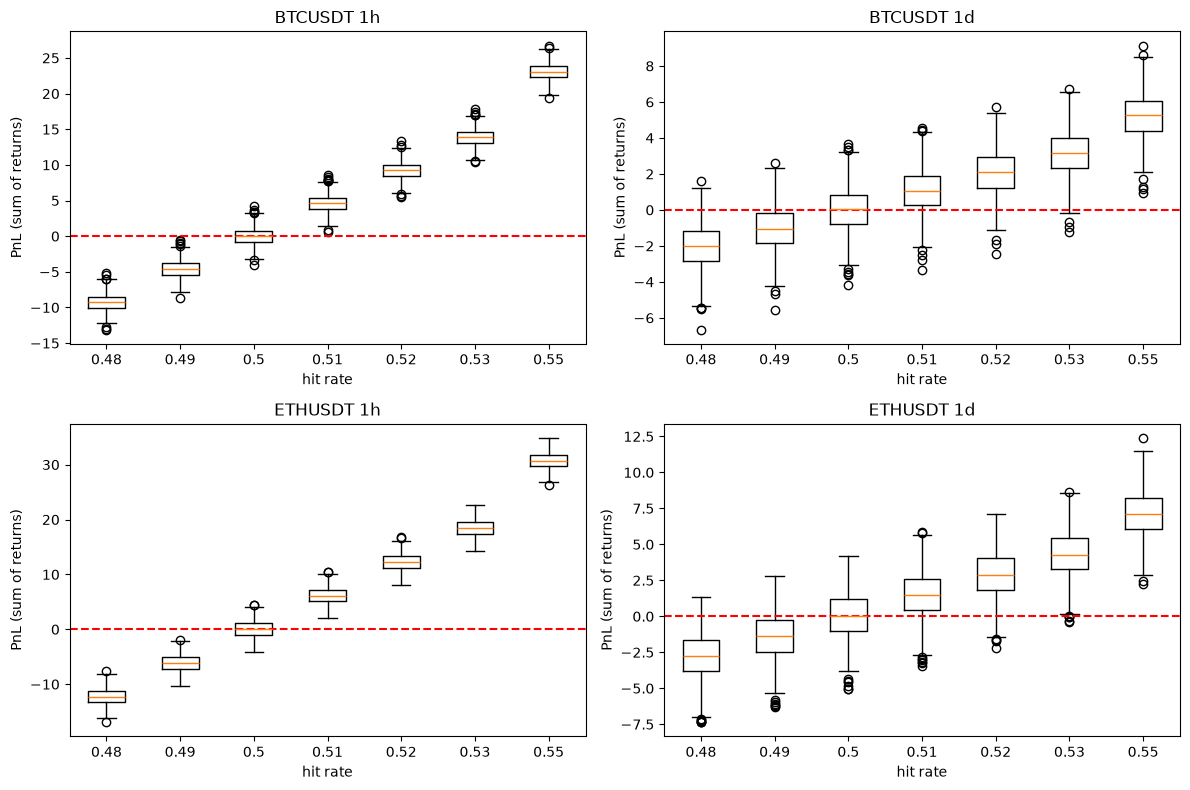

In [11]:
# Plot one box per hit rate for each coin and frequency.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (symbol, interval) in zip(axes.flat, PAIRS):
    mask = (
        (results["symbol"] == symbol)
        & (results["interval"] == interval)
        & (results["mode"] == "shuffle")
    )
    sub = results[mask]
    data = [sub[sub["hit_rate"] == h]["pnl"] for h in BOX_HIT_RATES]
    ax.boxplot(data, tick_labels=BOX_HIT_RATES)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{symbol} {interval}")
    ax.set_xlabel("hit rate")
    ax.set_ylabel("PnL (sum of returns)")
plt.tight_layout()
plt.show()

## Probability of a positive PnL vs hit rate

The spec formula for a 95% chance of positive PnL is
$p^* \approx \frac{1}{2} + \frac{z_q}{2 \sqrt{N}}$ with $z_q = 1.645$.

It assumes every trade moves by the same amount. Real returns have fat
tails, so a few large moves dominate the PnL. We correct for this with an
effective number of trades $N_{eff} = (\sum |r|)^2 / \sum r^2$ and plot both:
- gray dotted line: spec $p^*$ with $N$
- black dashed line: corrected $p^*$ with $N_{eff}$

In [12]:
# Compute N and N_eff for each coin and frequency.
rows = []
for symbol, interval in PAIRS:
    prices = tu.load_prices(symbol, interval, START, END)
    rets = tu.compute_returns(prices)
    n = len(rets)
    n_eff = tu.compute_effective_n(rets)
    rows.append(
        {
            "symbol": symbol,
            "interval": interval,
            "n": n,
            "n_eff": round(n_eff),
            "p_star_spec": round(tu.compute_min_hit_rate(n), 4),
            "p_star_eff": round(tu.compute_min_hit_rate(n_eff), 4),
        }
    )
n_stats = pd.DataFrame(rows).set_index(["symbol", "interval"])
n_stats

n  n_eff  p_star_spec  p_star_eff
symbol  interval                                       
BTCUSDT 1h        59127  21372       0.5034      0.5056
        1d         2464   1094       0.5166      0.5249
ETHUSDT 1h        59127  22710       0.5034      0.5055
        1d         2464   1131       0.5166      0.5245

In [13]:
# Compute P(PnL > 0) for each coin, frequency, mode, and hit rate.
prob = (
    results.assign(win=results["pnl"] > 0)
    .groupby(["symbol", "interval", "mode", "hit_rate"])["win"]
    .mean()
    .reset_index()
)
prob.pivot_table(
    index=["symbol", "interval", "mode"], columns="hit_rate", values="win"
)

hit_rate                    0.480  0.490  0.500  0.502  0.504  0.506  0.508  \
symbol  interval mode                                                         
BTCUSDT 1d       bernoulli  0.093  0.253  0.503  0.555  0.590  0.634  0.684   
                 shuffle    0.046  0.211  0.515  0.582  0.647  0.698  0.757   
        1h       bernoulli  0.000  0.001  0.505  0.731  0.887  0.961  0.992   
                 shuffle    0.000  0.000  0.501  0.768  0.927  0.989  0.999   
ETHUSDT 1d       bernoulli  0.099  0.250  0.505  0.546  0.600  0.635  0.687   
                 shuffle    0.038  0.204  0.503  0.582  0.645  0.713  0.779   
        1h       bernoulli  0.000  0.002  0.507  0.731  0.891  0.963  0.991   
                 shuffle    0.000  0.000  0.504  0.788  0.952  0.997  1.000   

hit_rate                    0.510  0.515  0.520  0.525  0.530  0.550  
symbol  interval mode                                                 
BTCUSDT 1d       bernoulli  0.738  0.819  0.883  0.938  0.976  0.999  
                 shuffle    0.820  0.906  0.957  0.985  0.995  1.000  
        1h       bernoulli  0.999  1.000  1.000  1.000  1.000  1.000  
                 shuffle    1.000  1.000  1.000  1.000  1.000  1.000  
ETHUSDT 1d       bernoulli  0.725  0.820  0.901  0.954  0.980  0.999  
                 shuffle    0.830  0.906  0.964  0.989  0.996  1.000  
        1h       bernoulli  0.999  1.000  1.000  1.000  1.000  1.000  
                 shuffle    1.000  1.000  1.000  1.000  1.000  1.000

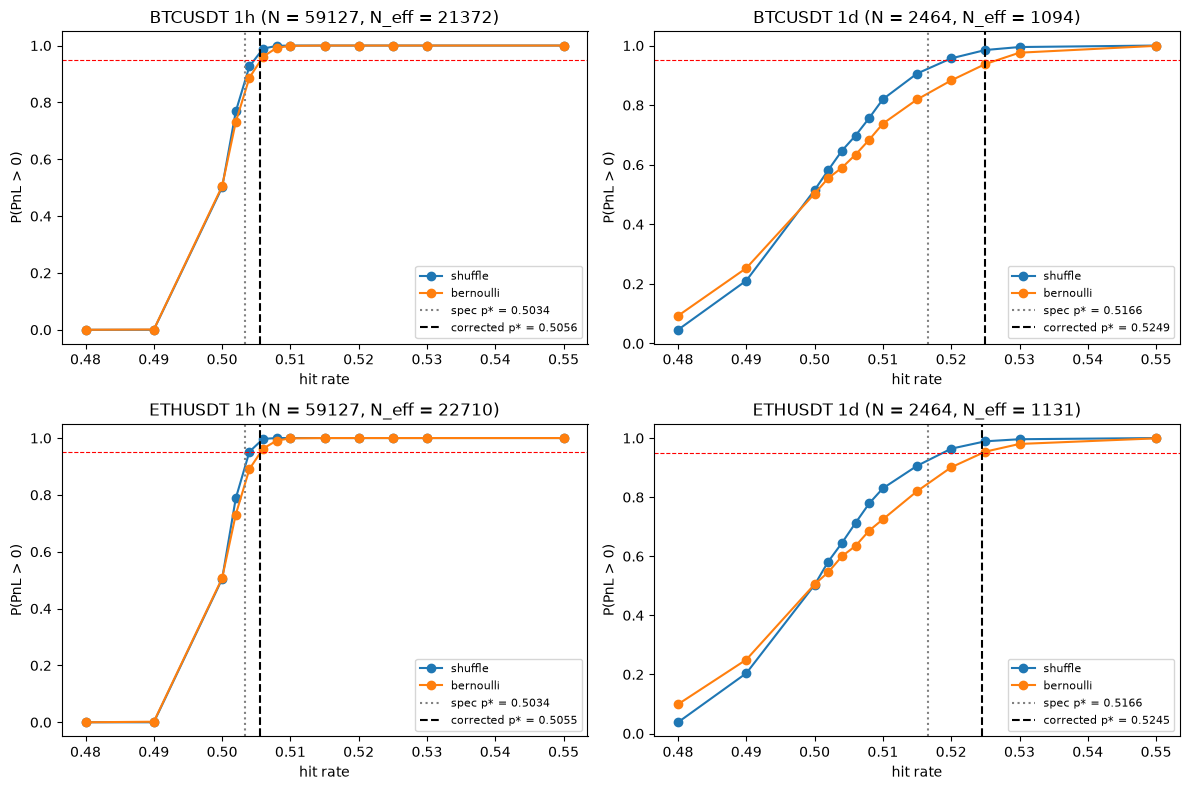

In [14]:
# Plot P(PnL > 0) for both modes against the spec and corrected p*.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (symbol, interval) in zip(axes.flat, PAIRS):
    for mode in MODES:
        mask = (
            (prob["symbol"] == symbol)
            & (prob["interval"] == interval)
            & (prob["mode"] == mode)
        )
        sub = prob[mask]
        ax.plot(sub["hit_rate"], sub["win"], marker="o", label=mode)
    stats = n_stats.loc[(symbol, interval)]
    label = f"spec p* = {stats['p_star_spec']:.4f}"
    ax.axvline(stats["p_star_spec"], color="gray", linestyle=":", label=label)
    label = f"corrected p* = {stats['p_star_eff']:.4f}"
    ax.axvline(stats["p_star_eff"], color="black", linestyle="--", label=label)
    ax.axhline(0.95, color="red", linestyle="--", linewidth=0.8)
    n, n_eff = int(stats["n"]), int(stats["n_eff"])
    ax.set_title(f"{symbol} {interval} (N = {n}, N_eff = {n_eff})")
    ax.set_xlabel("hit rate")
    ax.set_ylabel("P(PnL > 0)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
# Find the smallest simulated hit rate with P(PnL > 0) >= 95%.
crossing = (
    prob[prob["win"] >= 0.95]
    .groupby(["symbol", "interval", "mode"])["hit_rate"]
    .min()
    .unstack("mode")
)
crossing = crossing.join(n_stats[["p_star_spec", "p_star_eff"]])
crossing

bernoulli  shuffle  p_star_spec  p_star_eff
symbol  interval                                             
BTCUSDT 1d            0.530    0.520       0.5166      0.5249
        1h            0.506    0.506       0.5034      0.5056
ETHUSDT 1d            0.525    0.520       0.5166      0.5245
        1h            0.506    0.504       0.5034      0.5055

## Observations

- At a 50% hit rate the PnL is centered at zero, as it should be. Above that, the median PnL grows linearly with the hit rate.
- Hourly data is much more reliable than daily. Same 6.75 years, but 24x more trades. At 51%, every hourly simulation made money; only about 75-80% of the daily ones did.
- ETH makes more money than BTC at the same hit rate because its moves are bigger. The chance of making money is almost the same for both, though.
- Shuffle (Exercise 1) and bernoulli (the spec) give the same answer for 1h. For 1d they differ: shuffle needs about 52% for a 95% chance of profit, bernoulli about 52.5%.
- The spec formula for p* is too optimistic. At its value for 1h (0.5034), the real chance of profit is only about 80%, not 95%. The reason is fat tails: a few big moves dominate the PnL, so we effectively have fewer trades than N. Replacing N with N_eff = (sum of |r|)^2 / (sum of r^2) fixes it. We get p* = 0.5056 for 1h and about 0.525 for 1d, which is where the simulation actually crosses 95%.